# Phân tích dữ liệu Pima Diabetes

## 1.1.4. Thống kê mô tả

### 1. Đọc dữ liệu

In [1]:
import numpy as np
import pandas as pd
from scipy import stats

# Nạp dữ liệu Pima Diabetes
diabetes_data = pd.read_csv("data/diabetes.csv")

print("Kích thước dữ liệu:", diabetes_data.shape)

diabetes_data.head()

Kích thước dữ liệu: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 2. Kiểm tra dữ liệu ban đầu

Kiểm tra giá trị thiếu được ghi nhận dưới dạng NaN và số lượng
giá trị bằng 0 ở từng cột.

In [2]:
print("Kiểu dữ liệu:")
print(diabetes_data.dtypes)

print("\nSố giá trị thiếu được ghi nhận là NaN:")
print(diabetes_data.isna().sum())

print("\nSố giá trị bằng 0 ở từng cột:")
print((diabetes_data == 0).sum())

print("\nSố dòng trùng hoàn toàn:", diabetes_data.duplicated().sum())

print("\nSố quan sát theo nhãn Outcome:")
print(diabetes_data["Outcome"].value_counts().sort_index())

Kiểu dữ liệu:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Số giá trị thiếu được ghi nhận là NaN:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Số giá trị bằng 0 ở từng cột:
Pregnancies                 111
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype:

### 3. Xử lý các giá trị 0 không hợp lệ

Chuyển giá trị 0 trong Glucose, BloodPressure, SkinThickness,
Insulin và BMI thành NaN trên bản sao diabetes_clean.

Giữ nguyên giá trị 0 của Pregnancies và Outcome vì chúng hợp lệ.
Giữ toàn bộ 768 dòng; chưa điền giá trị thiếu hoặc loại bỏ dòng.

In [3]:
# Giữ nguyên dữ liệu gốc
diabetes_clean = diabetes_data.copy()

# Các cột coi giá trị 0 là phép đo thiếu
measurement_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]

diabetes_clean[measurement_columns] = (
    diabetes_clean[measurement_columns].replace(0, np.nan)
)

# Kiểm tra số lượng và tỷ lệ thiếu sau khi chuyển
missing_summary = pd.DataFrame({
    "Số giá trị thiếu": diabetes_clean.isna().sum(),
    "Tỷ lệ thiếu (%)": diabetes_clean.isna().mean() * 100
})

print("Kích thước dữ liệu:", diabetes_clean.shape)
missing_summary

Kích thước dữ liệu: (768, 9)


,Số giá trị thiếu,Tỷ lệ thiếu (%)
Pregnancies,0,0.000000
Glucose,5,0.651042
BloodPressure,35,4.557292
SkinThickness,227,29.557292
Insulin,374,48.697917
BMI,11,1.432292
DiabetesPedigreeFunction,0,0.000000
Age,0,0.000000
Outcome,0,0.000000


### 4. Các chỉ số thống kê mô tả

Các chỉ số được tính trên các giá trị không thiếu của từng
đặc trưng, nên số quan sát hợp lệ khác nhau giữa các cột.

Phương sai và độ lệch chuẩn trong bảng sử dụng ddof=0.
Giữ đầy đủ các giá trị mode đồng hạng.
Outcome được thống kê riêng vì là nhãn phân loại.

In [4]:
# Tách các đặc trưng khỏi nhãn Outcome
diabetes_features = diabetes_clean.drop(columns=["Outcome"])

# Thống kê trên các giá trị không thiếu của từng cột
diabetes_summary = diabetes_features.describe(
    percentiles=[0.25, 0.50, 0.60, 0.75]
).T

# Thống nhất cách tính với các bài trước
diabetes_summary["std"] = diabetes_features.std(ddof=0)
diabetes_summary["variance"] = diabetes_features.var(ddof=0)

diabetes_summary["mode"] = [
    diabetes_features[column].mode().tolist()
    for column in diabetes_summary.index
]

diabetes_summary["range"] = (
    diabetes_summary["max"] - diabetes_summary["min"]
)
diabetes_summary["IQR"] = (
    diabetes_summary["75%"] - diabetes_summary["25%"]
)

diabetes_summary = diabetes_summary[
    [
        "count", "mean", "50%", "mode", "variance", "std",
        "min", "max", "range", "25%", "60%", "75%", "IQR"
    ]
]

diabetes_summary

,count,mean,50%,mode,variance,std,min,max,range,25%,60%,75%,IQR
Pregnancies,768.0,3.845052,3.0000,[1],11.339272,3.367384,0.000,17.00,17.000,1.00000,4.0000,6.00000,5.0000
Glucose,763.0,121.686763,117.0000,"[99.0, 100.0]",931.203324,30.515624,44.000,199.00,155.000,99.00000,125.0000,141.00000,42.0000
BloodPressure,733.0,72.405184,72.0000,[70.0],153.108677,12.373709,24.000,122.00,98.000,64.00000,75.0000,80.00000,16.0000
SkinThickness,541.0,29.153420,29.0000,[32.0],109.564263,10.467295,7.000,99.00,92.000,22.00000,32.0000,36.00000,14.0000
Insulin,394.0,155.548223,125.0000,[105.0],14071.897421,118.625029,14.000,846.00,832.000,76.25000,145.8000,190.00000,113.7500
BMI,757.0,32.457464,32.3000,[32.0],47.892114,6.920413,18.200,67.10,48.900,27.50000,33.8000,36.60000,9.1000
DiabetesPedigreeFunction,768.0,0.471876,0.3725,"[0.254, 0.258]",0.109636,0.331113,0.078,2.42,2.342,0.24375,0.4542,0.62625,0.3825
Age,768.0,33.240885,29.0000,[22],138.122964,11.752573,21.000,81.00,60.000,24.00000,33.0000,41.00000,17.0000


### 5. Phân bố nhãn Outcome

Outcome = 0: không mắc bệnh tiểu đường theo nhãn của bộ dữ liệu.
Outcome = 1: mắc bệnh tiểu đường theo nhãn của bộ dữ liệu.

Tỷ lệ được tính trên 768 quan sát và chỉ mô tả bộ dữ liệu này.

In [5]:
outcome_count = (
    diabetes_clean["Outcome"].value_counts().sort_index()
)

outcome_summary = pd.DataFrame({
    "Số quan sát": outcome_count,
    "Tỷ lệ (%)": outcome_count / len(diabetes_clean) * 100
})

outcome_summary.index.name = "Outcome"

outcome_summary

,Số quan sát,Tỷ lệ (%)
Outcome,,
0,500,65.104167
1,268,34.895833


### 6. Xác định các điểm ngoài giới hạn IQR

Sử dụng giới hạn Q1 - 1,5 × IQR và Q3 + 1,5 × IQR.

Tỷ lệ điểm ngoài giới hạn được tính trên số quan sát không thiếu
của từng đặc trưng. Các điểm này được giữ lại để phân tích.

In [6]:
q1 = diabetes_features.quantile(0.25)
q3 = diabetes_features.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (
    (diabetes_features < lower_bound)
    | (diabetes_features > upper_bound)
)

outlier_count = outlier_mask.sum()
valid_count = diabetes_features.count()

diabetes_outliers = pd.DataFrame({
    "Giới hạn dưới": lower_bound,
    "Giới hạn trên": upper_bound,
    "Số quan sát hợp lệ": valid_count,
    "Số giá trị ngoài giới hạn": outlier_count,
    "Tỷ lệ trên quan sát hợp lệ (%)": (
        outlier_count / valid_count * 100
    )
})

diabetes_outliers

,Giới hạn dưới,Giới hạn trên,Số quan sát hợp lệ,Số giá trị ngoài giới hạn,Tỷ lệ trên quan sát hợp lệ (%)
Pregnancies,-6.500,13.500,768,4,0.520833
Glucose,36.000,204.000,763,0,0.000000
BloodPressure,40.000,104.000,733,14,1.909959
SkinThickness,1.000,57.000,541,3,0.554529
Insulin,-94.375,360.625,394,24,6.091371
BMI,13.850,50.250,757,8,1.056803
DiabetesPedigreeFunction,-0.330,1.200,768,29,3.776042
Age,-1.500,66.500,768,9,1.171875


### 7. Nhận xét thống kê mô tả


- Dữ liệu gốc có 768 quan sát, 9 cột, không có NaN và không có
  dòng trùng hoàn toàn.
- Coi giá trị 0 ở Glucose, BloodPressure, SkinThickness, Insulin
  và BMI là phép đo thiếu, chuyển thành NaN trên bản sao.
  Giữ nguyên giá trị 0 ở Pregnancies và Outcome.
- Insulin thiếu 374 quan sát (48,70%); SkinThickness thiếu
  227 quan sát (29,56%). Các chỉ số được tính trên giá trị
  hợp lệ riêng từng cột, không điền thêm hoặc xóa toàn bộ dòng.
- Glucose có trung bình khoảng 121,69 và trung vị 117,
  tính trên 763 quan sát hợp lệ.
- Insulin có trung bình khoảng 155,55, trung vị 125 và độ lệch
  chuẩn 118,63. Kết quả chỉ mô tả 394 quan sát có phép đo hợp lệ;
  cần lưu ý tỷ lệ thiếu cao khi diễn giải.
- Age có trung bình khoảng 33,24 tuổi, trung vị 29 tuổi;
  độ tuổi trong dữ liệu nằm từ 21 đến 81.
- Outcome có 500 quan sát nhãn 0 (65,10%) và 268 quan sát
  nhãn 1 (34,90%). Đây là tỷ lệ trong bộ dữ liệu,
  không đại diện cho tỷ lệ mắc bệnh của toàn bộ dân số.
- Theo quy tắc IQR, Insulin có 24 giá trị ngoài giới hạn
  (6,09% trên quan sát hợp lệ), DiabetesPedigreeFunction có
  29 giá trị (3,78%). Các giá trị này được giữ lại vì chưa
  có bằng chứng là lỗi.
- Phương sai và độ lệch chuẩn dùng ddof=0. Không so sánh
  trực tiếp độ lệch chuẩn giữa các biến khác đơn vị hoặc thang đo.

## 1.2.3. Trực quan hóa dữ liệu Pima Diabetes

### Phân bố nhãn Outcome

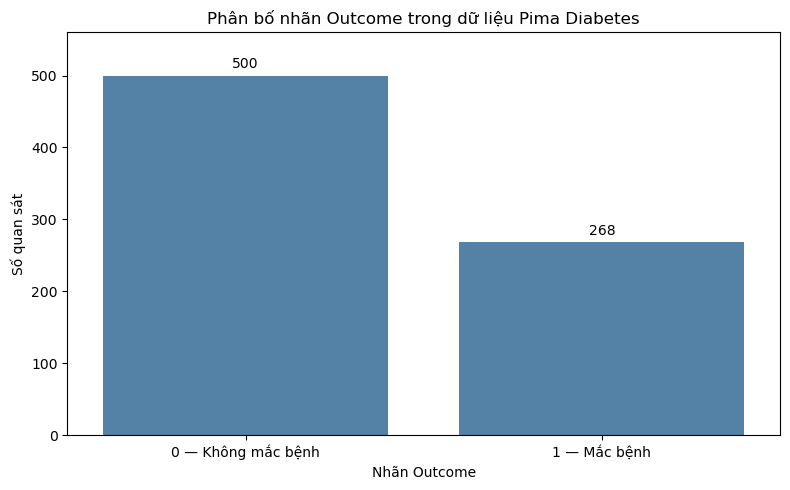

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=diabetes_clean,
    x="Outcome",
    order=[0, 1],
    color="steelblue",
    ax=ax
)

ax.set_title("Phân bố nhãn Outcome trong dữ liệu Pima Diabetes")
ax.set_xlabel("Nhãn Outcome")
ax.set_ylabel("Số quan sát")
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 — Không mắc bệnh", "1 — Mắc bệnh"])

ax.bar_label(ax.containers[0], padding=3)
ax.margins(y=0.12)

fig.tight_layout()
plt.show()

### Phân bố các đặc trưng trong dữ liệu Pima Diabetes

Mỗi histogram sử dụng các giá trị không thiếu của từng đặc trưng.
Các giá trị NaN được bỏ qua khi vẽ; chưa thực hiện điền giá trị thiếu.

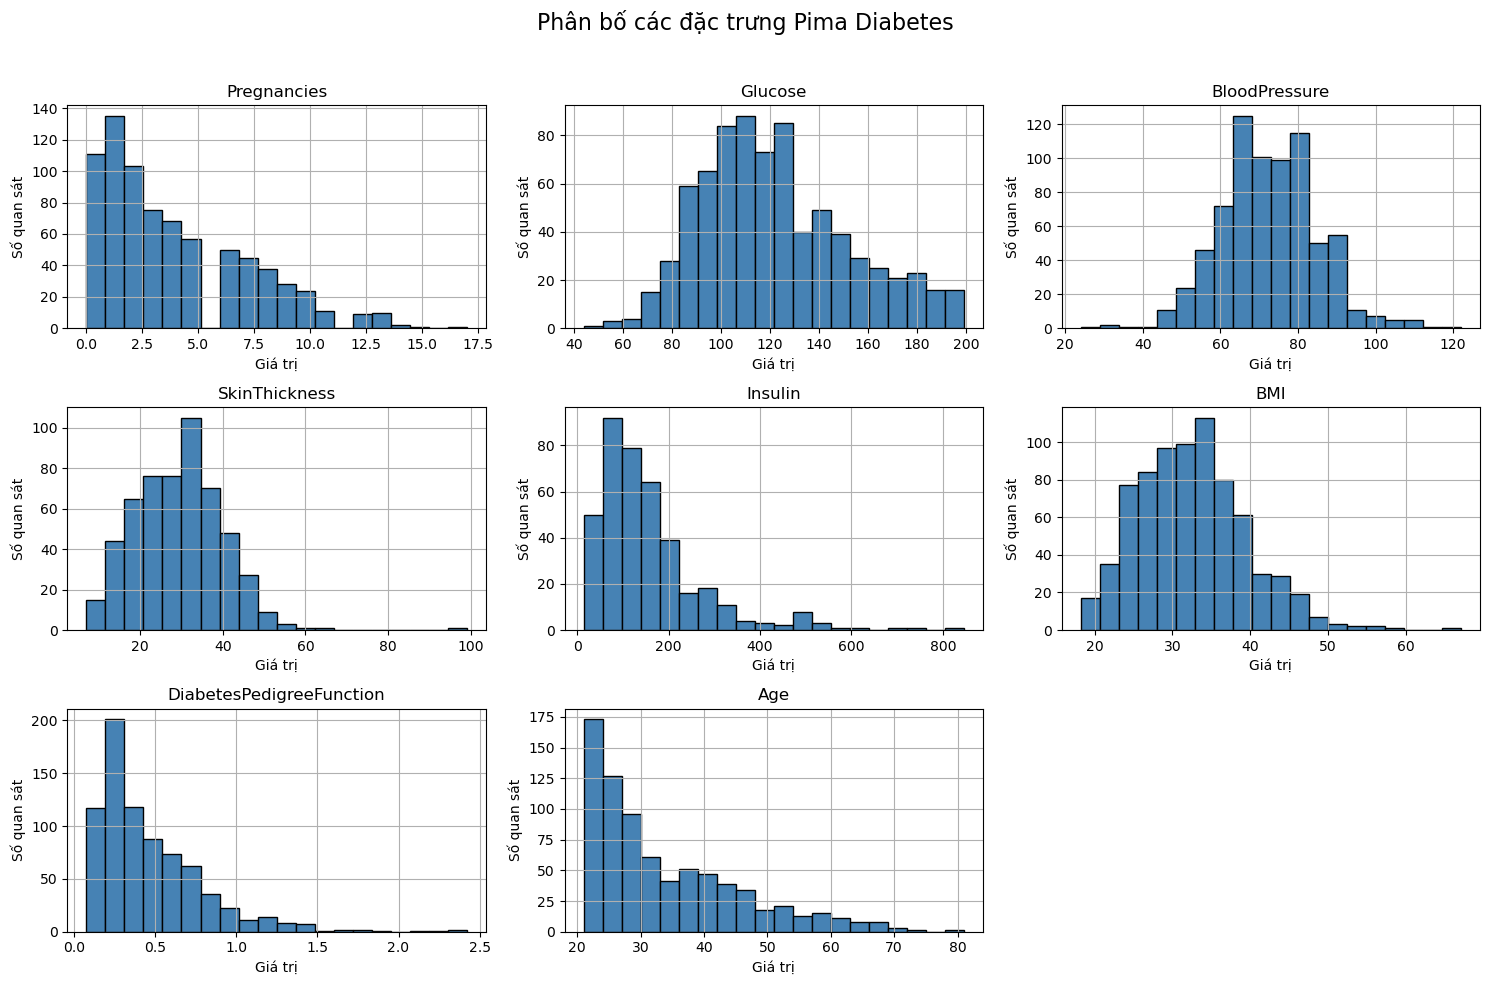

In [8]:
diabetes_features = diabetes_clean.drop(columns="Outcome")

diabetes_features.hist(
    bins=20,
    figsize=(15, 10),
    layout=(3, 3),
    color="steelblue",
    edgecolor="black"
)

fig = plt.gcf()
fig.suptitle("Phân bố các đặc trưng Pima Diabetes", fontsize=16)

for ax in fig.axes:
    if ax.get_visible():
        ax.set_xlabel("Giá trị")
        ax.set_ylabel("Số quan sát")

fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Boxplot các đặc trưng Pima Diabetes

Mỗi biểu đồ sử dụng các quan sát không thiếu của từng đặc trưng.
Các điểm ngoài râu hộp được đánh dấu theo quy tắc 1,5 × IQR
và được giữ lại để phân tích.

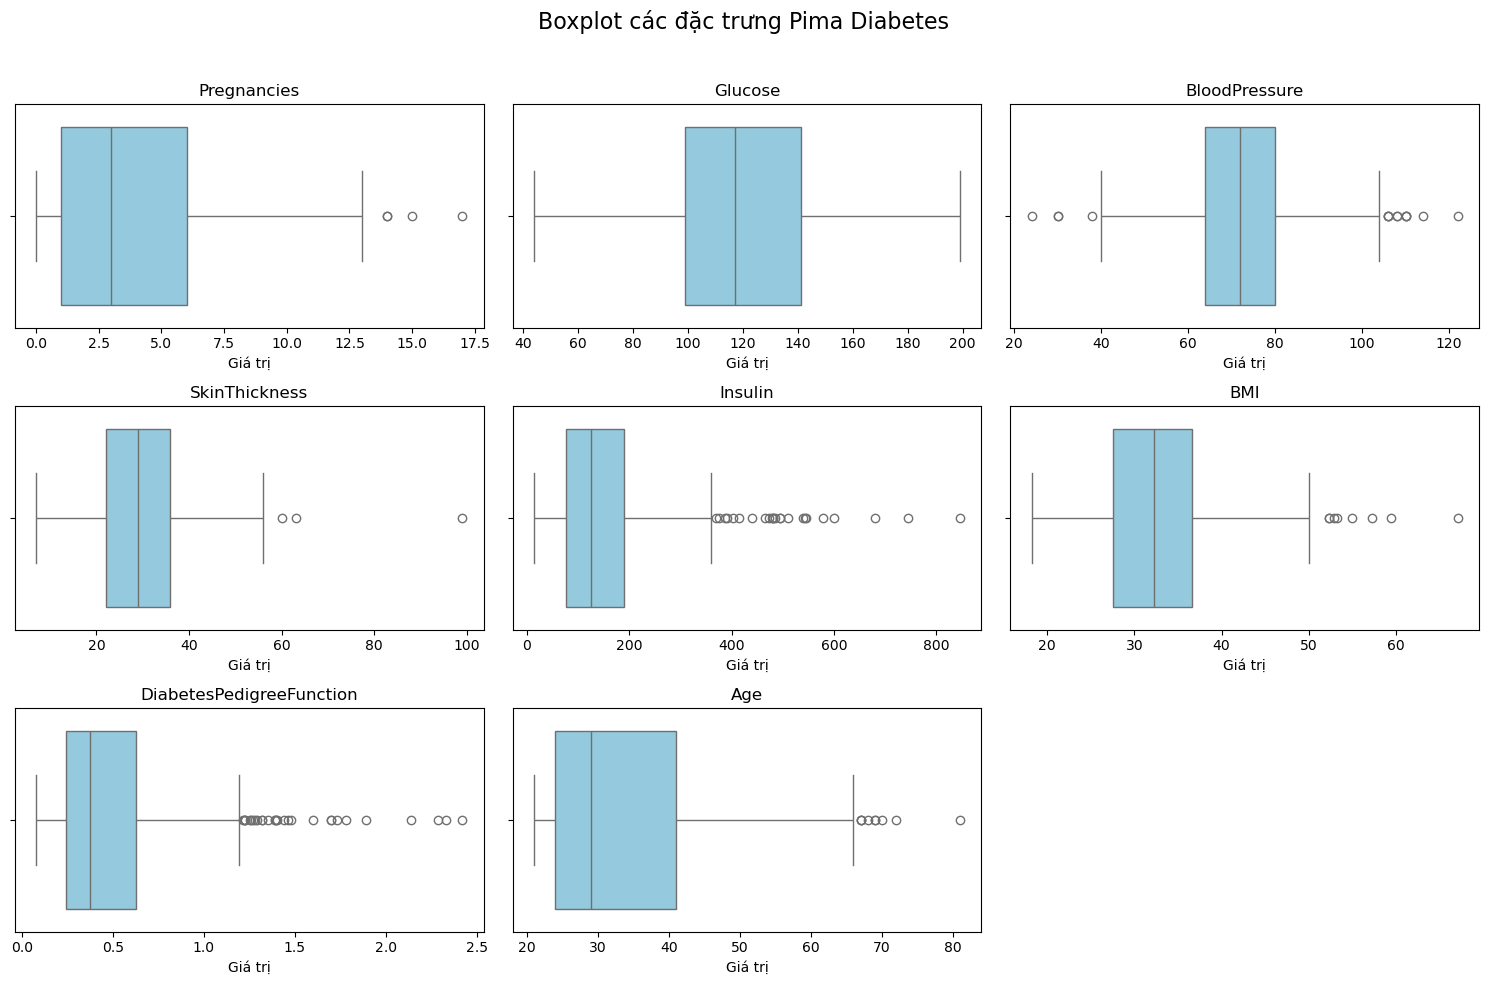

In [9]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.ravel()

for ax, column in zip(axes, diabetes_features.columns):
    sns.boxplot(
        x=diabetes_features[column].dropna(),
        color="skyblue",
        whis=1.5,
        ax=ax
    )
    ax.set_title(column)
    ax.set_xlabel("Giá trị")

# Ẩn ô dư
for ax in axes[len(diabetes_features.columns):]:
    ax.set_visible(False)

fig.suptitle("Boxplot các đặc trưng Pima Diabetes", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### Phân bố Glucose và BMI theo nhãn Outcome

Mỗi biểu đồ sử dụng các quan sát không thiếu của biến tương ứng.
So sánh trung vị và độ phân tán giữa hai nhóm Outcome.

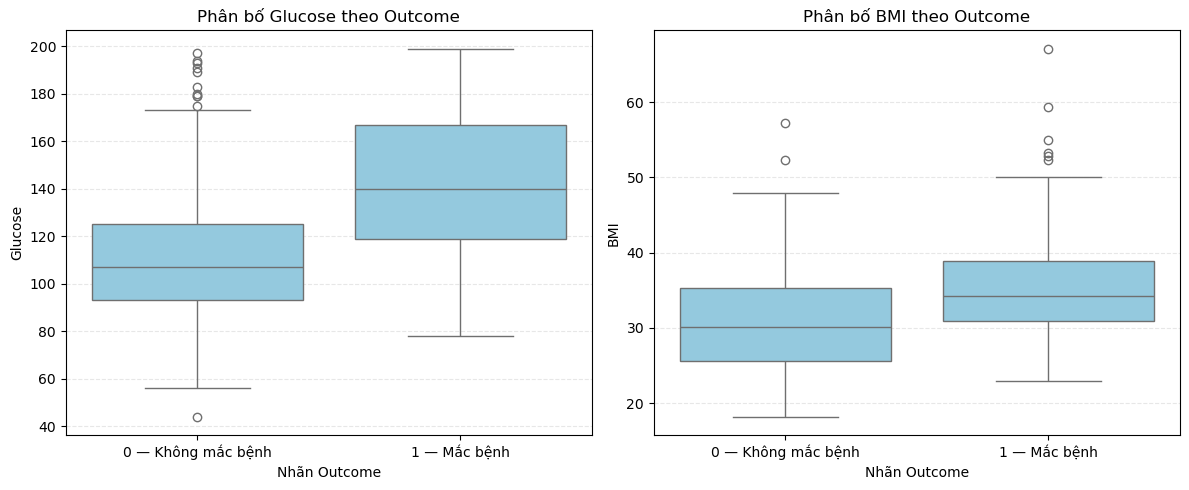

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, column in zip(axes, ["Glucose", "BMI"]):
    sns.boxplot(
        data=diabetes_clean,
        x="Outcome",
        y=column,
        order=[0, 1],
        color="skyblue",
        ax=ax
    )

    ax.set_title(f"Phân bố {column} theo Outcome")
    ax.set_xlabel("Nhãn Outcome")
    ax.set_ylabel(column)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["0 — Không mắc bệnh", "1 — Mắc bệnh"])
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Mối liên hệ giữa Glucose và BMI theo Outcome

Chỉ sử dụng các dòng có đầy đủ Glucose, BMI và Outcome để vẽ.
Dữ liệu diabetes_clean vẫn được giữ nguyên.

Số quan sát dùng vẽ scatter: 752


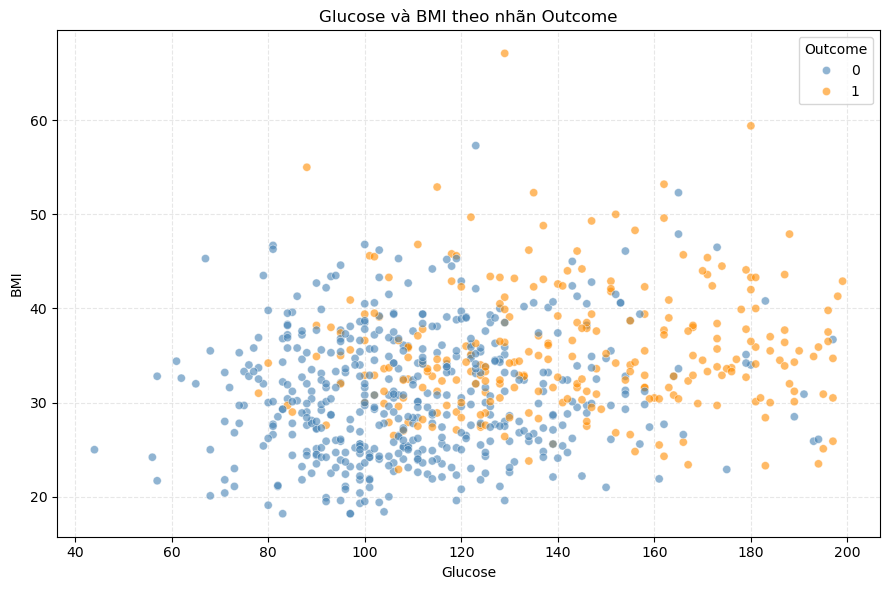

In [11]:
diabetes_scatter = diabetes_clean.dropna(
    subset=["Glucose", "BMI", "Outcome"]
)

print("Số quan sát dùng vẽ scatter:", len(diabetes_scatter))

fig, ax = plt.subplots(figsize=(9, 6))

sns.scatterplot(
    data=diabetes_scatter,
    x="Glucose",
    y="BMI",
    hue="Outcome",
    hue_order=[0, 1],
    palette={0: "steelblue", 1: "darkorange"},
    alpha=0.6,
    s=35,
    ax=ax
)

ax.set_title("Glucose và BMI theo nhãn Outcome")
ax.set_xlabel("Glucose")
ax.set_ylabel("BMI")
ax.legend(title="Outcome")
ax.grid(linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

### Ma trận tương quan giữa các biến

Tính tương quan Pearson trên diabetes_clean.
Mỗi cặp biến sử dụng các dòng không thiếu ở cả hai biến,
vì vậy số quan sát có thể khác nhau giữa các cặp.

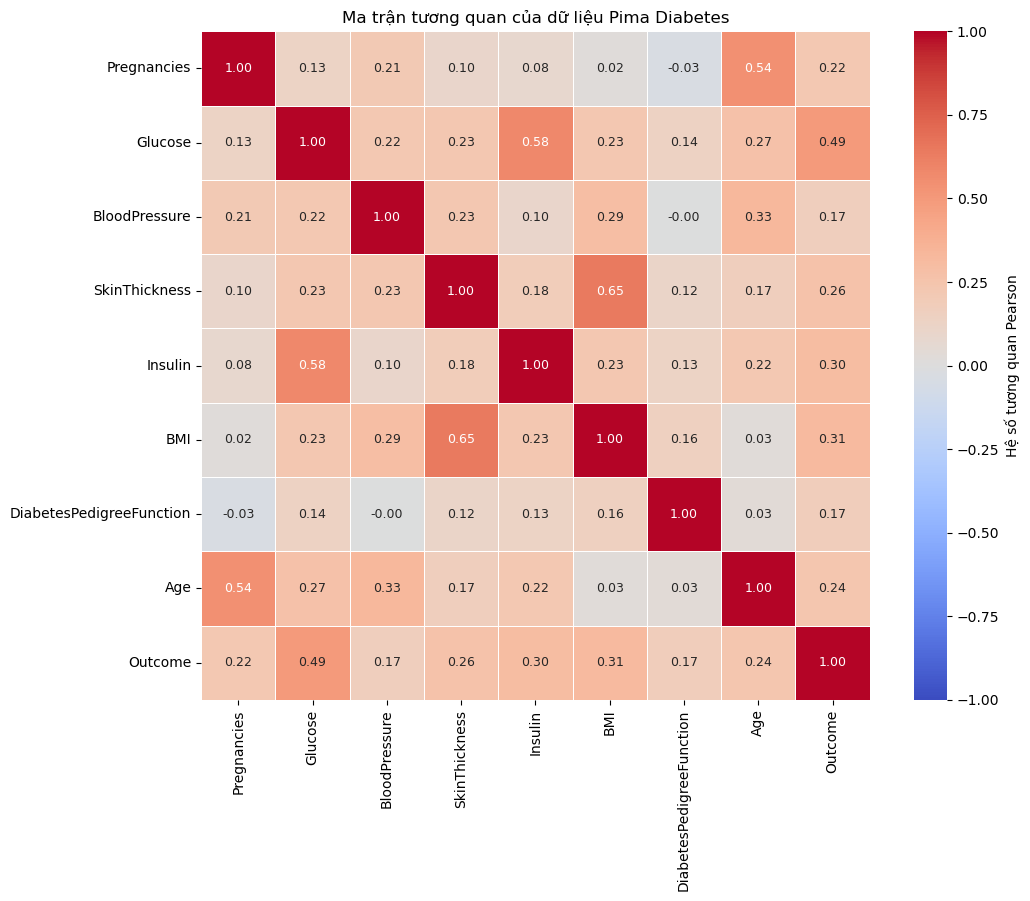

In [12]:
diabetes_corr = diabetes_clean.corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    diabetes_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    annot_kws={"size": 9},
    cbar_kws={"label": "Hệ số tương quan Pearson"},
    ax=ax
)

ax.set_title("Ma trận tương quan của dữ liệu Pima Diabetes")
fig.tight_layout()
plt.show()

### Nhận xét về trực quan hóa

- Bộ dữ liệu có 500 quan sát Outcome = 0 (65,10%) và
  268 quan sát Outcome = 1 (34,90%). Các tỷ lệ này chỉ mô tả
  bộ dữ liệu, không đại diện cho tỷ lệ mắc bệnh trong dân số.
- Histogram cho thấy Insulin, DiabetesPedigreeFunction,
  Age và Pregnancies có phân bố lệch phải. BloodPressure
  khá đối xứng quanh vùng trung tâm.
- Boxplot thể hiện các điểm ngoài giới hạn 1,5 × IQR,
  nổi bật ở Insulin và DiabetesPedigreeFunction.
  Các điểm này được giữ lại vì chưa có bằng chứng là dữ liệu sai.
- Nhóm Outcome = 1 có trung vị Glucose và BMI cao hơn
  nhóm Outcome = 0, nhưng phân bố giữa hai nhóm vẫn chồng lấn.
- Scatter plot sử dụng 752 quan sát có đầy đủ Glucose và BMI.
  Nhóm Outcome = 1 xuất hiện nhiều hơn ở vùng Glucose cao,
  nhưng hai nhóm chưa tách biệt rõ ràng.
- Trong các đặc trưng, Glucose có tương quan Pearson với
  Outcome cao nhất, khoảng 0,49; tiếp theo là BMI khoảng 0,31
  và Insulin khoảng 0,30.
- SkinThickness và BMI có tương quan thuận khoảng 0,65;
  Glucose và Insulin khoảng 0,58; Pregnancies và Age khoảng 0,54.
- Các biểu đồ và hệ số tương quan sử dụng dữ liệu sau khi
  chuyển các giá trị 0 không hợp lệ thành NaN. Số quan sát
  hợp lệ khác nhau giữa các biến và giữa các cặp biến.
- Insulin thiếu khoảng 48,70% và SkinThickness thiếu khoảng
  29,56%, nên kết quả liên quan đến hai biến này cần được
  diễn giải thận trọng do khả năng sai lệch từ dữ liệu thiếu.
- Các kết quả thể hiện mối liên hệ trong dữ liệu, không chứng minh
  quan hệ nhân quả và không đủ để đưa ra kết luận chẩn đoán.